In [1]:
import sys
sys.dont_write_bytecode = True

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import pingouin as pg

from sklearn.feature_selection import mutual_info_regression

from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', None)

* **instant**: Record index  
* **dteday**: Date  
* **season**: Seasons
    * 1: springer  
    * 2: summer  
    * 3: fall  
    * 4:winter    
* **yr**: Year   
    * 0: 2011  
    * 1: 2012    
* **mnth**: Month (1 to 12)  
* **hr**: Hour (0 to 23)  
* **holiday**: weather day is holiday or not (extracted from Holiday Schedule)  
* **weekday**: Day of the week  
* **workingday**: If day is neither weekend nor holiday is 1, otherwise is 0.  
* **weathersit**: (extracted from Freemeteo)  
    * 1: Clear, Few clouds, Partly cloudy, Partly cloudy  
    * 2: Mist + Cloudy, Mist + Broken clouds, Mist + Few clouds, Mist  
    * 3: Light Snow, Light Rain + Thunderstorm + Scattered clouds, Light Rain + Scattered clouds  
    * 4: Heavy Rain + Ice Pallets + Thunderstorm + Mist, Snow + Fog  
* **temp**: Normalized temperature in Celsius. The values are derived via (t-t_min)/(t_max-t_min), t_min=-8, t_max=+39 (only in hourly scale)  
* **atemp**: Normalized feeling temperature in Celsius. The values are derived via (t-t_min)/(t_max-t_min), t_min=-16, t_max=+50 (only in hourly scale)  
* **hum**: Normalized humidity. The values are divided to 100 (max)  
* **windspeed**: Normalized wind speed. The values are divided to 67 (max)  
* **casual**: count of casual users  
* **registered**: count of registered users  
* **cnt**: count of total rental bikes including both casual and registered  

In [2]:
rent = pd.read_csv("data/hour.csv")
display(rent.head(5))
display(rent.tail(5))
display(rent.info())
display(rent.describe())
display(rent.isna().sum())

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
17374,17375,2012-12-31,1,1,12,19,0,1,1,2,0.26,0.2576,0.60,0.1642,11,108,119
17375,17376,2012-12-31,1,1,12,20,0,1,1,2,0.26,0.2576,0.60,0.1642,8,81,89
17376,17377,2012-12-31,1,1,12,21,0,1,1,1,0.26,0.2576,0.60,0.1642,7,83,90
17377,17378,2012-12-31,1,1,12,22,0,1,1,1,0.26,0.2727,0.56,0.1343,13,48,61
17378,17379,2012-12-31,1,1,12,23,0,1,1,1,0.26,0.2727,0.65,0.1343,12,37,49


<class 'pandas.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     17379 non-null  int64  
 1   dteday      17379 non-null  str    
 2   season      17379 non-null  int64  
 3   yr          17379 non-null  int64  
 4   mnth        17379 non-null  int64  
 5   hr          17379 non-null  int64  
 6   holiday     17379 non-null  int64  
 7   weekday     17379 non-null  int64  
 8   workingday  17379 non-null  int64  
 9   weathersit  17379 non-null  int64  
 10  temp        17379 non-null  float64
 11  atemp       17379 non-null  float64
 12  hum         17379 non-null  float64
 13  windspeed   17379 non-null  float64
 14  casual      17379 non-null  int64  
 15  registered  17379 non-null  int64  
 16  cnt         17379 non-null  int64  
dtypes: float64(4), int64(12), str(1)
memory usage: 2.4 MB


None

,instant,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,17379.0000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000
mean,8690.0000,2.501640,0.502561,6.537775,11.546752,0.028770,3.003683,0.682721,1.425283,0.496987,0.475775,0.627229,0.190098,35.676218,153.786869,189.463088
std,5017.0295,1.106918,0.500008,3.438776,6.914405,0.167165,2.005771,0.465431,0.639357,0.192556,0.171850,0.192930,0.122340,49.305030,151.357286,181.387599
min,1.0000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.020000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,4345.5000,2.000000,0.000000,4.000000,6.000000,0.000000,1.000000,0.000000,1.000000,0.340000,0.333300,0.480000,0.104500,4.000000,34.000000,40.000000
50%,8690.0000,3.000000,1.000000,7.000000,12.000000,0.000000,3.000000,1.000000,1.000000,0.500000,0.484800,0.630000,0.194000,17.000000,115.000000,142.000000
75%,13034.5000,3.000000,1.000000,10.000000,18.000000,0.000000,5.000000,1.000000,2.000000,0.660000,0.621200,0.780000,0.253700,48.000000,220.000000,281.000000
max,17379.0000,4.000000,1.000000,12.000000,23.000000,1.000000,6.000000,1.000000,4.000000,1.000000,1.000000,1.000000,0.850700,367.000000,886.000000,977.000000


instant       0
dteday        0
season        0
yr            0
mnth          0
hr            0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64

In [3]:
rentt = rent.copy(deep=True)

rentt['dteday'] = pd.to_datetime(rentt['dteday'], format='mixed')
rentt['dteday'] = rentt['dteday'] + pd.to_timedelta(rentt['hr'], unit='h')
rentt['dteday'] = rentt['dteday'].dt.floor('h')

rentt = rentt.drop(columns=['instant', 'casual', 'registered', 'yr'])
rentt = rentt.sort_values(by='dteday', ascending=True)
rentt = rentt.reset_index(drop=True)

for c in rentt.columns:
    if rentt[c].dtype == 'float64':
        rentt[c] = rentt[c].astype('float32')
    elif rentt[c].dtype == 'int64':
        rentt[c] = rentt[c].astype('int32')
    else:
        pass

In [5]:
display(rentt.head(5))
display(rentt.tail(5))
display(rentt.info())
display(rentt.describe())

,dteday,season,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,cnt
0,2011-01-01 00:00:00,1,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,16
1,2011-01-01 01:00:00,1,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,40
2,2011-01-01 02:00:00,1,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,32
3,2011-01-01 03:00:00,1,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,13
4,2011-01-01 04:00:00,1,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,1


,dteday,season,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,cnt
17374,2012-12-31 19:00:00,1,12,19,0,1,1,2,0.26,0.2576,0.60,0.1642,119
17375,2012-12-31 20:00:00,1,12,20,0,1,1,2,0.26,0.2576,0.60,0.1642,89
17376,2012-12-31 21:00:00,1,12,21,0,1,1,1,0.26,0.2576,0.60,0.1642,90
17377,2012-12-31 22:00:00,1,12,22,0,1,1,1,0.26,0.2727,0.56,0.1343,61
17378,2012-12-31 23:00:00,1,12,23,0,1,1,1,0.26,0.2727,0.65,0.1343,49


<class 'pandas.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 13 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   dteday      17379 non-null  datetime64[us]
 1   season      17379 non-null  int32         
 2   mnth        17379 non-null  int32         
 3   hr          17379 non-null  int32         
 4   holiday     17379 non-null  int32         
 5   weekday     17379 non-null  int32         
 6   workingday  17379 non-null  int32         
 7   weathersit  17379 non-null  int32         
 8   temp        17379 non-null  float32       
 9   atemp       17379 non-null  float32       
 10  hum         17379 non-null  float32       
 11  windspeed   17379 non-null  float32       
 12  cnt         17379 non-null  int32         
dtypes: datetime64[us](1), float32(4), int32(8)
memory usage: 950.5 KB


None

,dteday,season,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,cnt
count,17379,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000
mean,2012-01-02 15:41:22.858622,2.501640,6.537775,11.546752,0.028770,3.003683,0.682721,1.425283,0.496987,0.475775,0.627229,0.190098,189.463088
min,2011-01-01 00:00:00,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.020000,0.000000,0.000000,0.000000,1.000000
25%,2011-07-04 22:30:00,2.000000,4.000000,6.000000,0.000000,1.000000,0.000000,1.000000,0.340000,0.333300,0.480000,0.104500,40.000000
50%,2012-01-02 21:00:00,3.000000,7.000000,12.000000,0.000000,3.000000,1.000000,1.000000,0.500000,0.484800,0.630000,0.194000,142.000000
75%,2012-07-02 06:30:00,3.000000,10.000000,18.000000,0.000000,5.000000,1.000000,2.000000,0.660000,0.621200,0.780000,0.253700,281.000000
max,2012-12-31 23:00:00,4.000000,12.000000,23.000000,1.000000,6.000000,1.000000,4.000000,1.000000,1.000000,1.000000,0.850700,977.000000
std,NaN,1.106918,3.438776,6.914405,0.167165,2.005771,0.465431,0.639357,0.192556,0.171850,0.192930,0.122340,181.387599


In [6]:
train_ratio = 0.75
val_ratio = 0.1

train_idx = int(rentt.shape[0]*train_ratio)
val_idx = int(rentt.shape[0]*(train_ratio+val_ratio))

trainvaldf = rentt[:val_idx]

In [7]:
num_cols = ['hr', 'temp', 'atemp', 'hum', 'windspeed', 'cnt']
cat_cols = ['mnth', 'holiday', 'weekday', 'workingday', 'weathersit']
nontarget_features = num_cols[:-1] + cat_cols
target_feature = ['cnt']
cat_mask = [True if c in cat_cols else False for c in nontarget_features]

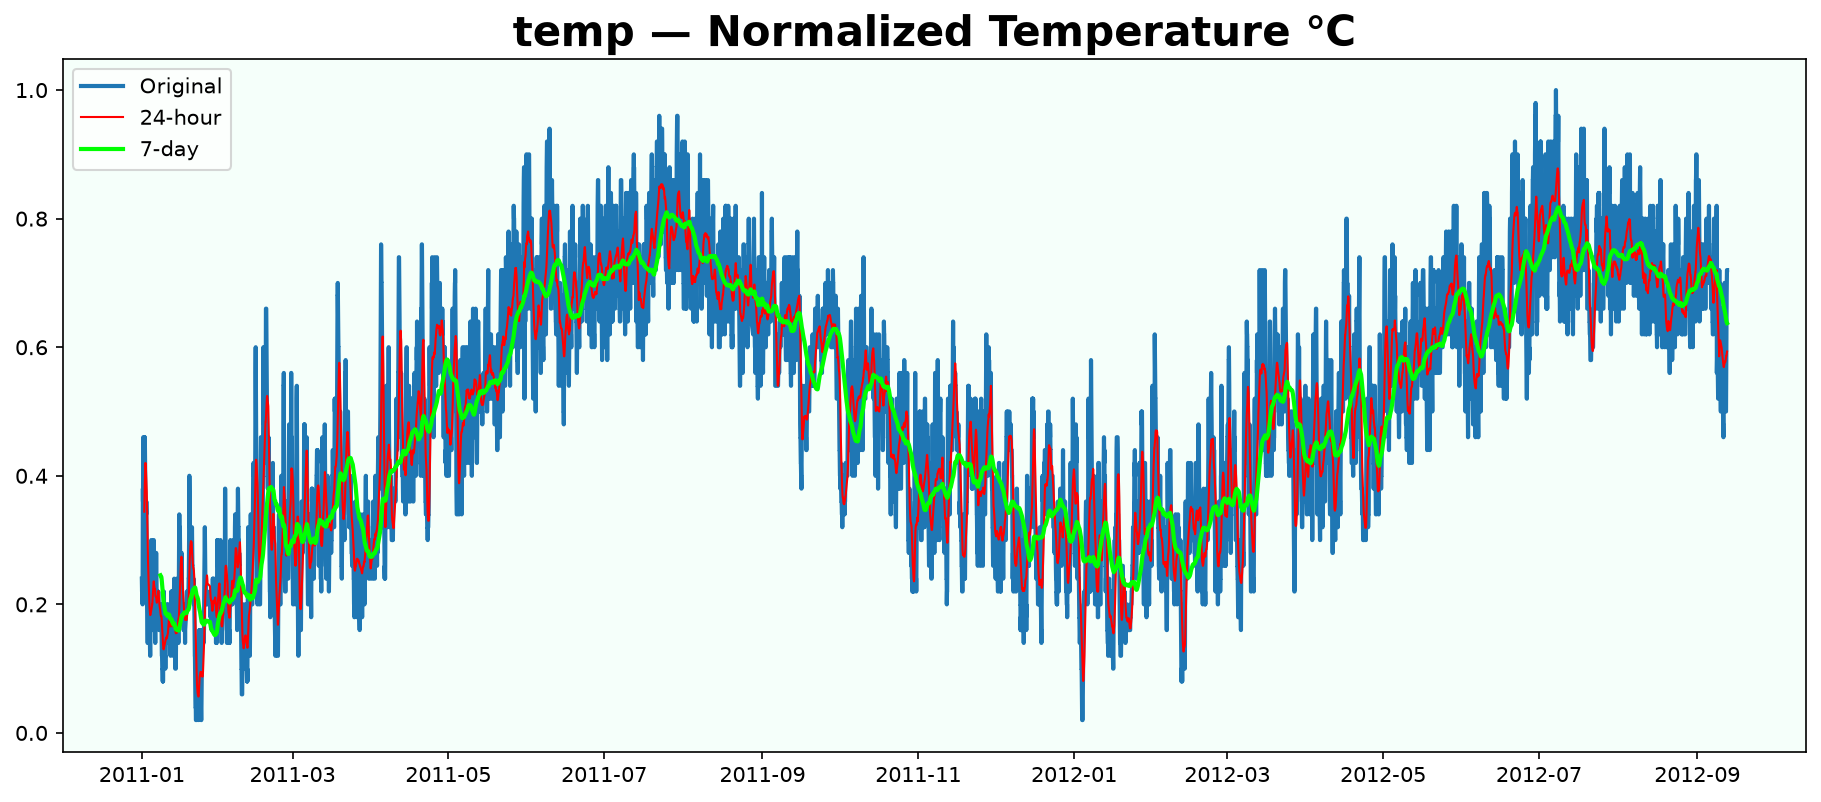

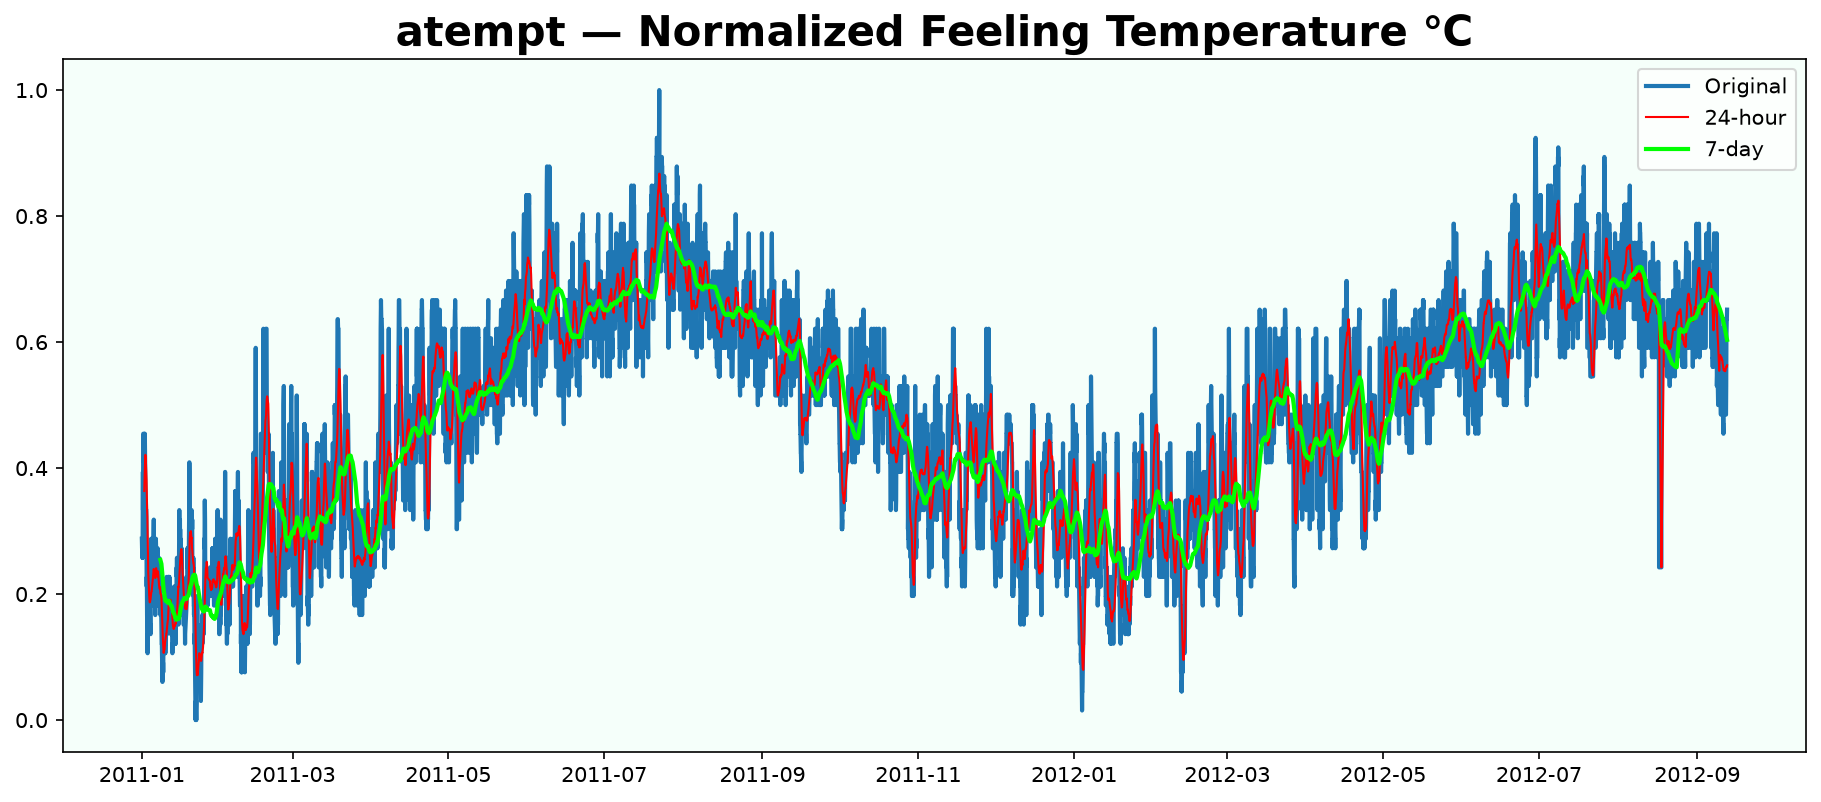

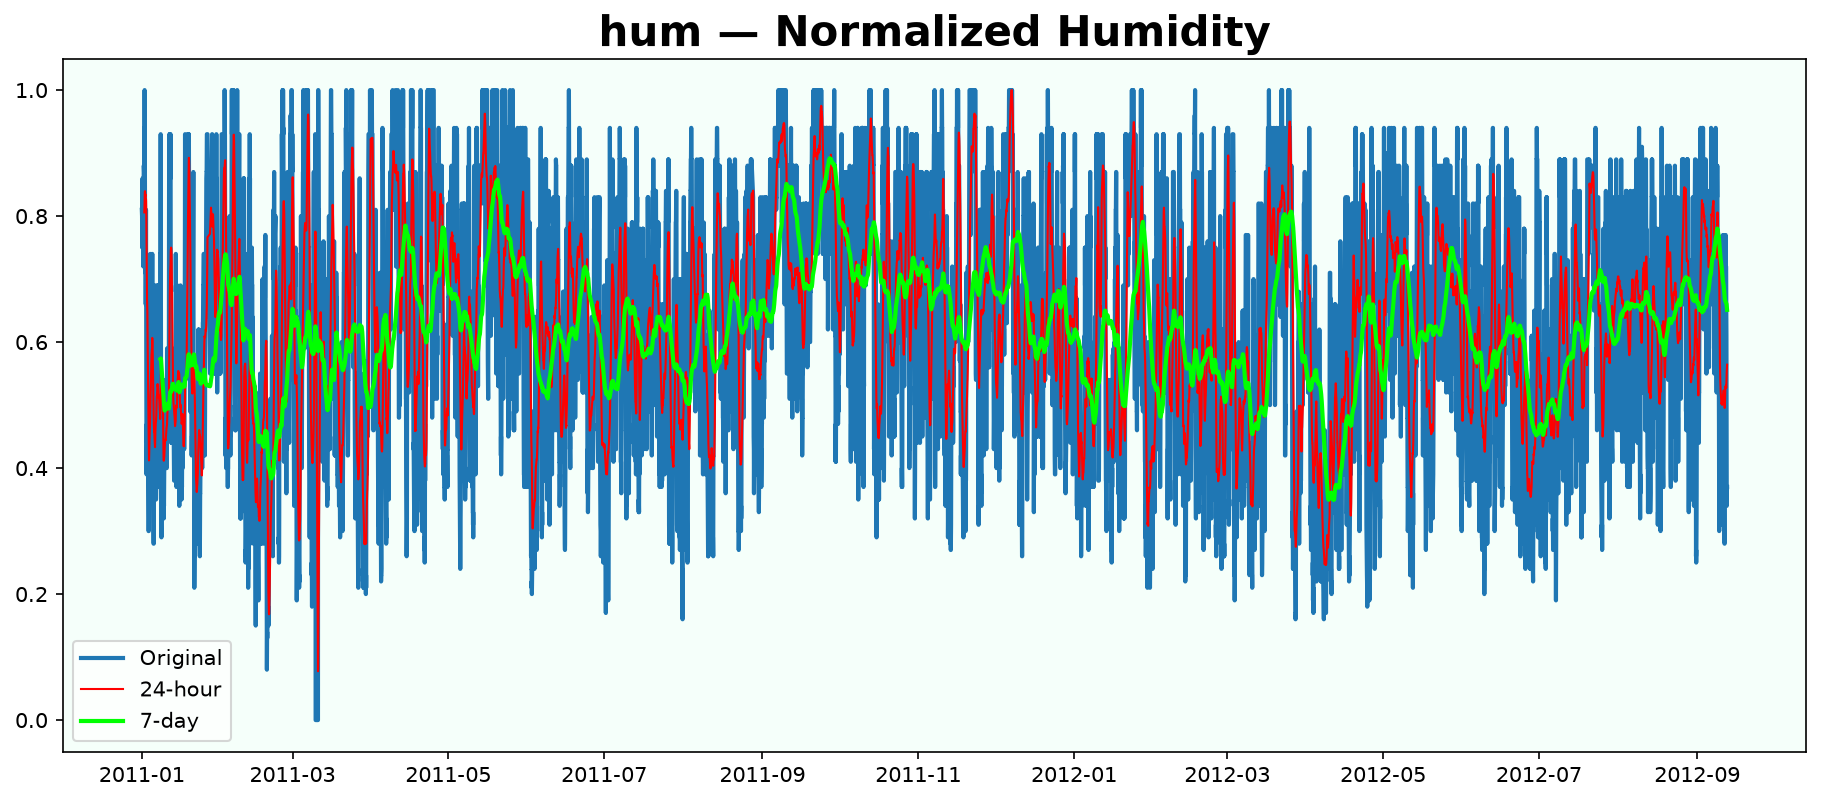

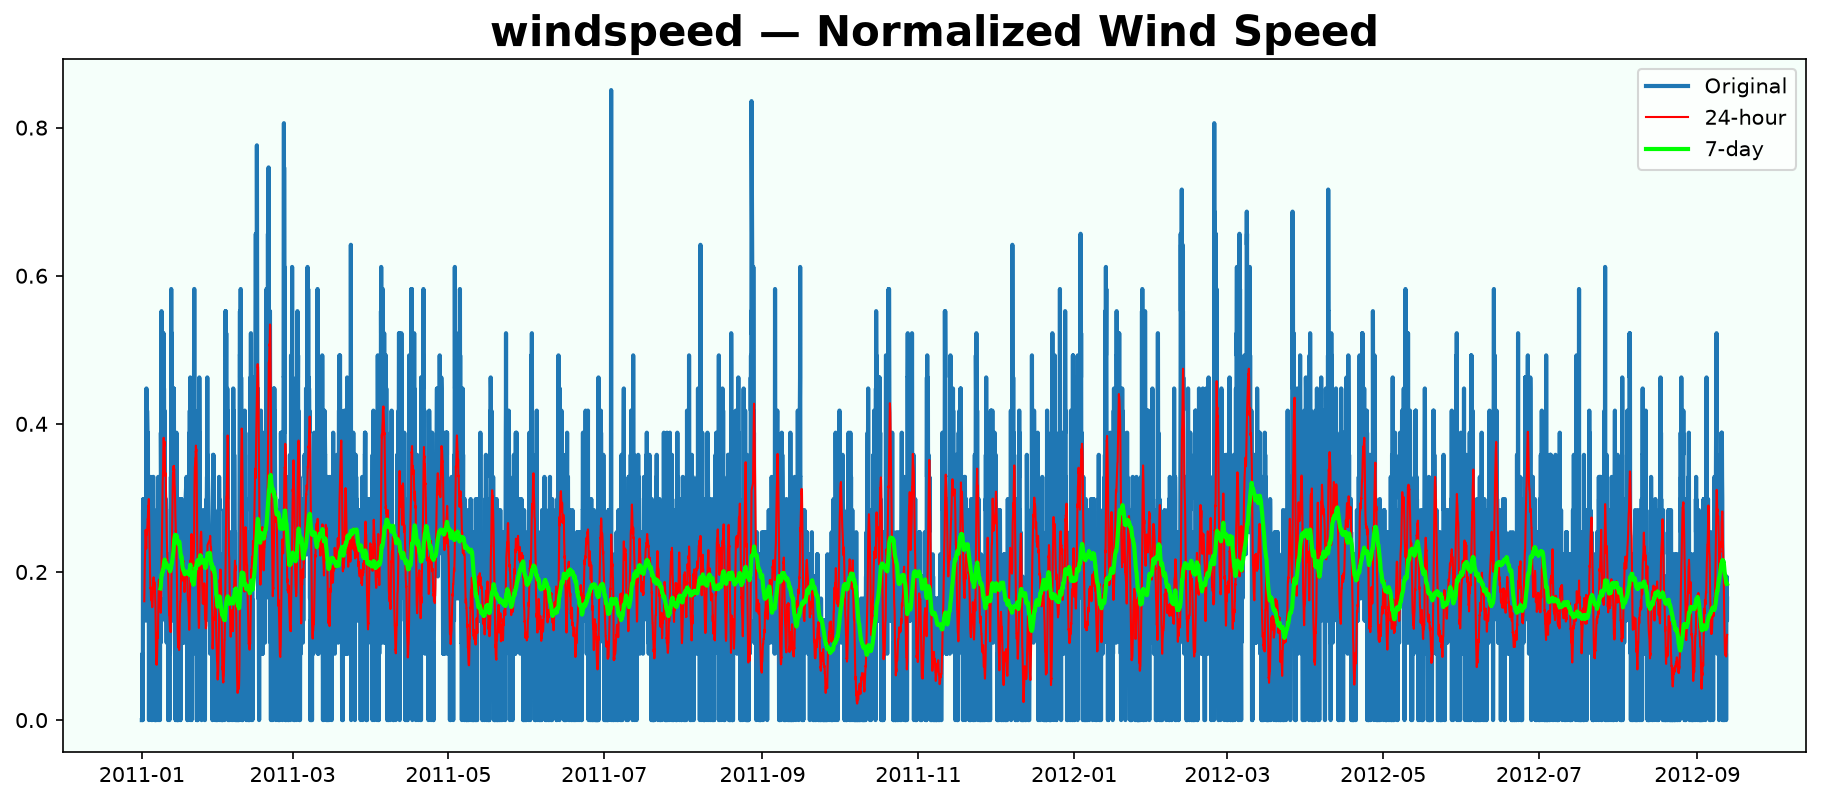

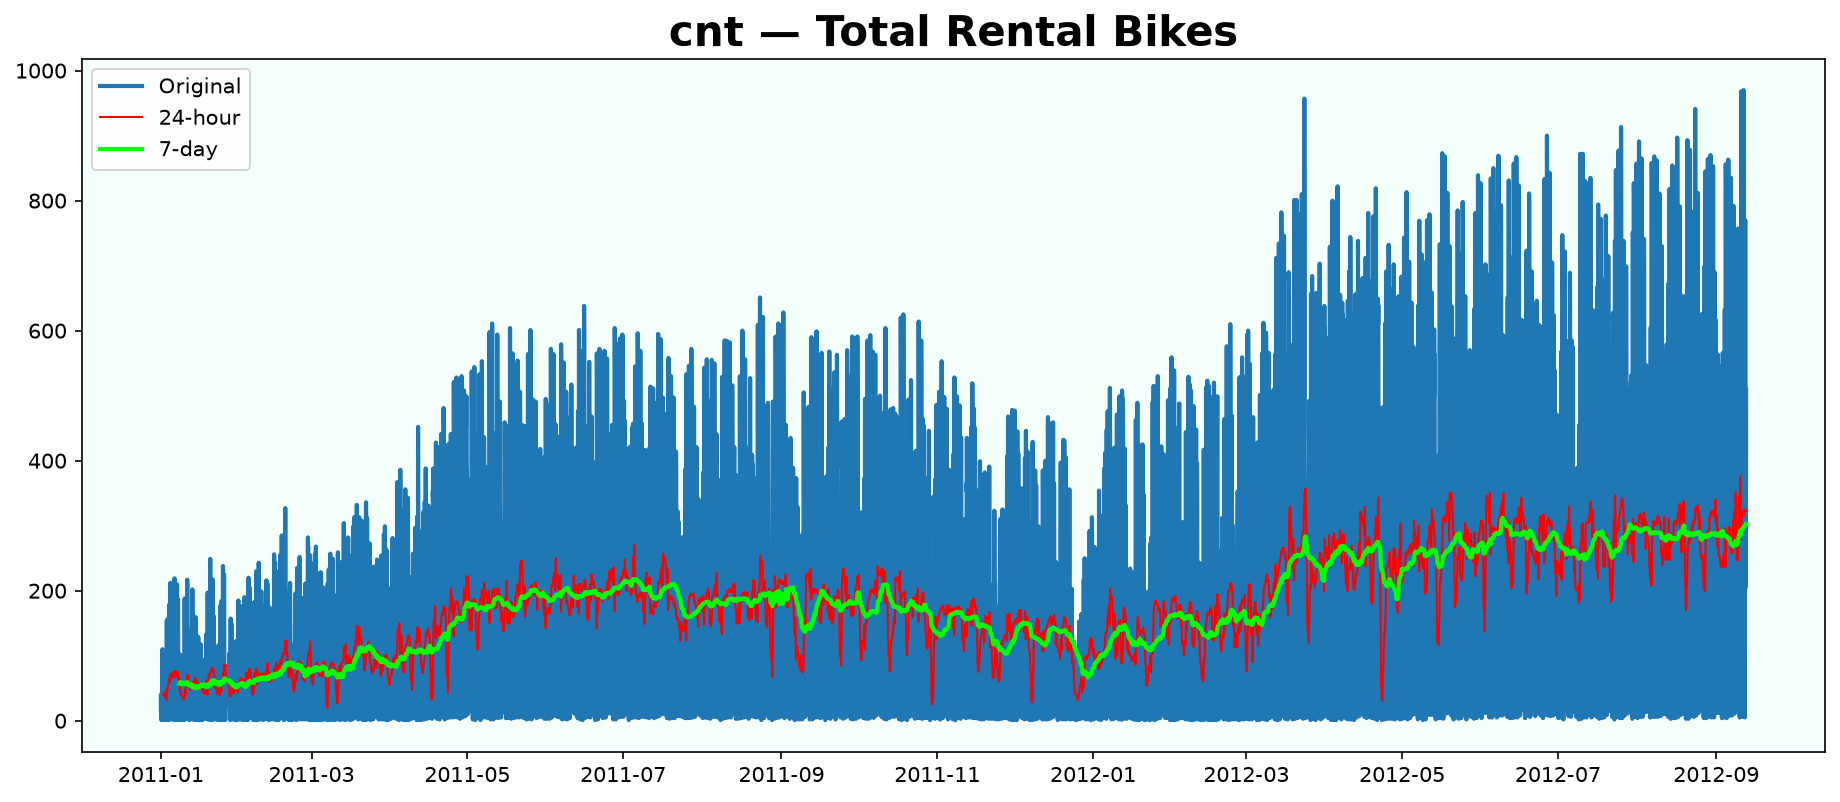

In [8]:
num_corrected_labels = {'temp': 'temp — Normalized Temperature ℃', 'atemp':'atempt — Normalized Feeling Temperature ℃', 'hum':'hum — Normalized Humidity', 'windspeed':'windspeed — Normalized Wind Speed', 'cnt':'cnt — Total Rental Bikes'}

for c in num_cols[1:]:
    plt.figure(figsize=(15,6), dpi=150)
    plt.title(num_corrected_labels.get(c), fontsize=20, fontweight='bold')
    plt.plot(trainvaldf['dteday'], trainvaldf[c], lw=2, color='tab:blue', label="Original")
    plt.plot(trainvaldf['dteday'], trainvaldf[c].rolling(window=24).mean(), lw=1, color='red', label="24-hour")
    plt.plot(trainvaldf['dteday'], trainvaldf[c].rolling(window=24*7).mean(), lw=2, color='lime', label="7-day")
    plt.gca().set_facecolor('#F5FFFA')
    plt.legend()
    plt.show()

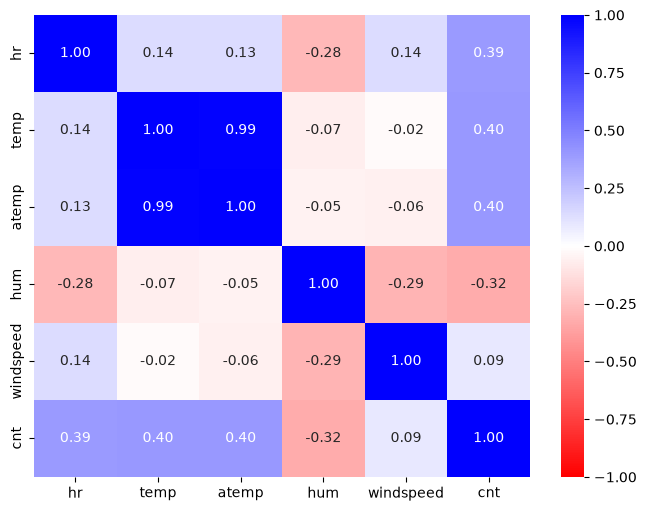

In [9]:
plt.figure(figsize=(8,6), dpi=100)
sns.heatmap(rentt[num_cols].corr(), annot=True, vmin=-1, vmax=1, cmap="bwr_r", fmt=".2f", annot_kws={"size": 10})
plt.show()

hr            0.623213
atemp         0.144974
temp          0.143956
hum           0.097531
mnth          0.076909
weekday       0.023323
windspeed     0.018094
workingday    0.015529
weathersit    0.008637
holiday       0.001647
dtype: float64

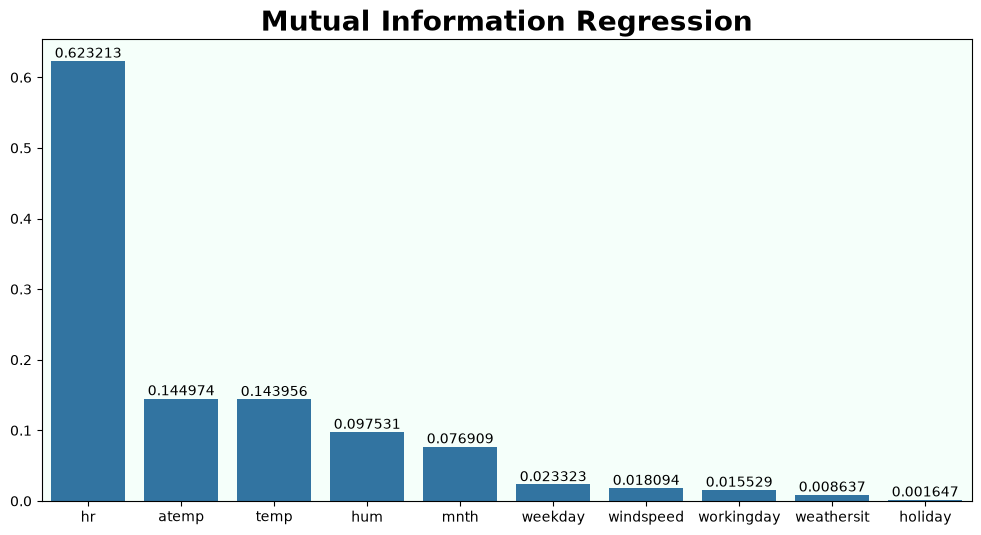

In [11]:
mi_scores = mutual_info_regression(rentt[nontarget_features].values, rentt[target_feature].values.ravel(), discrete_features=cat_mask, random_state=26)
mi_series = pd.Series(mi_scores, index=nontarget_features).sort_values(ascending=False)
display(mi_series)

plt.figure(figsize=(12,6))
plt.title("Mutual Information Regression", fontsize=20, fontweight='bold')
ax = sns.barplot(data=mi_series, errorbar=None, color='tab:blue')
ax.bar_label(ax.containers[0], fmt="%.6f")
plt.gca().set_facecolor('#F5FFFA')
plt.show()


In [12]:
results = []

for col in cat_cols:
    n_categories = trainvaldf[col].nunique()

    if n_categories < 2:
        continue

    anova = pg.anova(
        data=trainvaldf,
        dv="cnt",
        between=col,
        detailed=True,
        effsize="n2"
    )
    row = anova.loc[
        anova["Source"] == col
    ].iloc[0]

    welch = pg.welch_anova(
        data=trainvaldf,
        dv="cnt",
        between=col
    )

    result = {
        "Feature": col,
        "Categories": n_categories,
        "ANOVA_P": row["p_unc"],
        "Welch_P": welch["p_unc"].iloc[0],
        "Eta_Squared": row["n2"]
    }

    results.append(result)


results_df = pd.DataFrame(results)
results_df = results_df.sort_values(
    "Eta_Squared",
    ascending=False
)
results_df = results_df.reset_index(drop=True)
results_df = results_df.set_index("Feature")

display(results_df)

,Categories,ANOVA_P,Welch_P,Eta_Squared
Feature,,,,
mnth,12,1.011570e-285,0.000000e+00,0.088200
weathersit,4,2.725152e-72,1.562403e-08,0.022424
weekday,7,5.218404e-02,4.364444e-02,0.000844
workingday,2,1.439629e-03,1.062378e-03,0.000687
holiday,2,3.110178e-03,1.074752e-03,0.000592


* **ANOVA p-value**: significant if below **0.05**.  
* **Welch ANOVA p-value**: significant if below **0.05**.
* [CRITICAL] **Eta squared (η²)**: associated if above **0.01**.

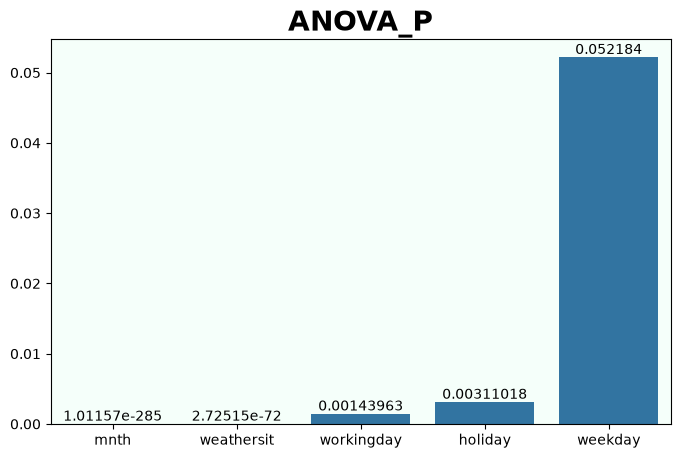

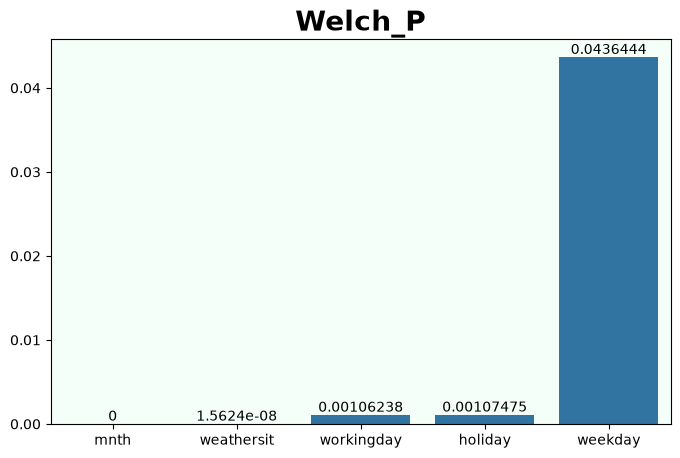

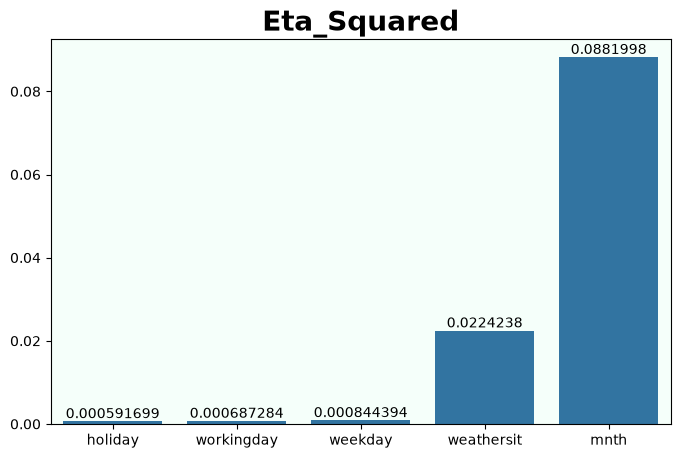

In [14]:
for c in results_df.columns[1:]:
    plt.figure(figsize=(8,5))
    plt.title(c, fontsize=20, fontweight='bold')
    ax = sns.barplot(data=results_df[c].sort_values(), errorbar=None, color='tab:blue')
    ax.bar_label(ax.containers[0])
    plt.gca().set_facecolor('#F5FFFA')
    plt.xlabel("")
    plt.ylabel("")
    plt.show()

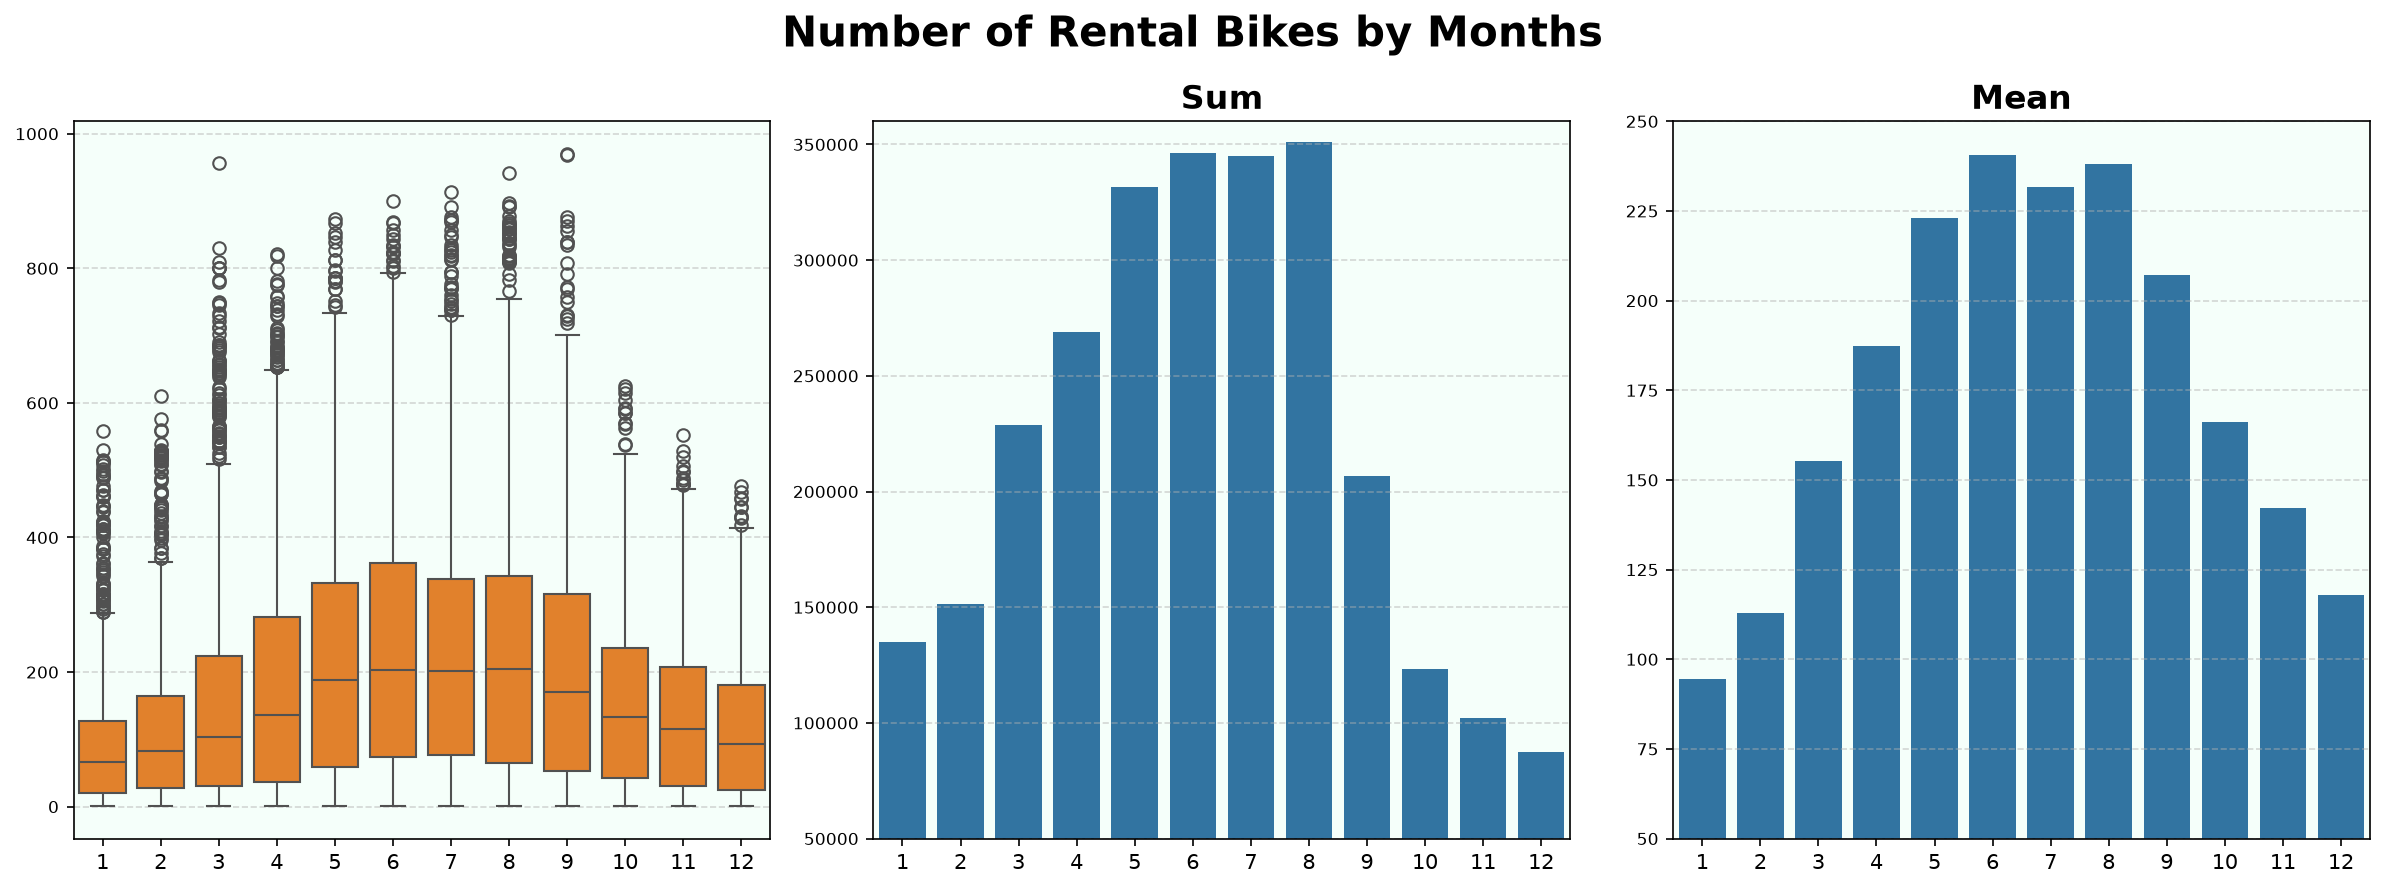

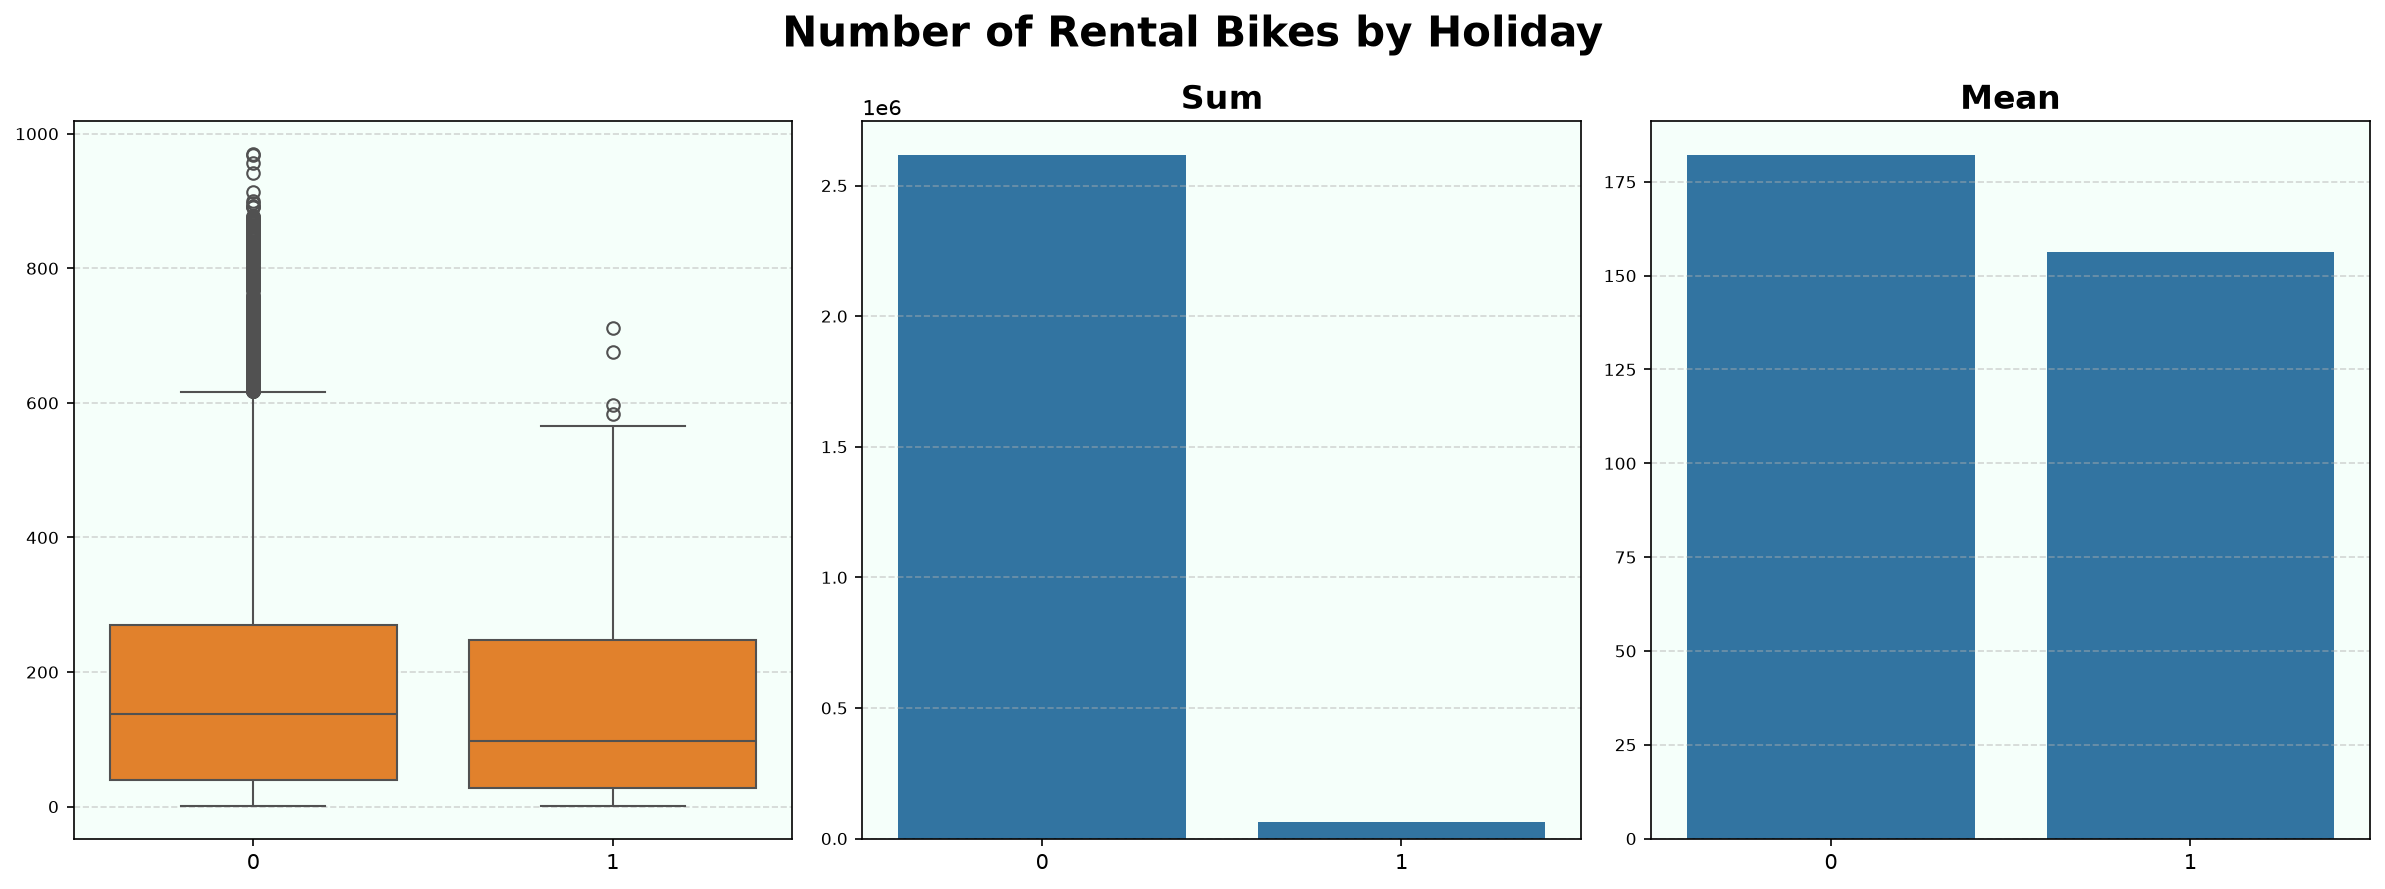

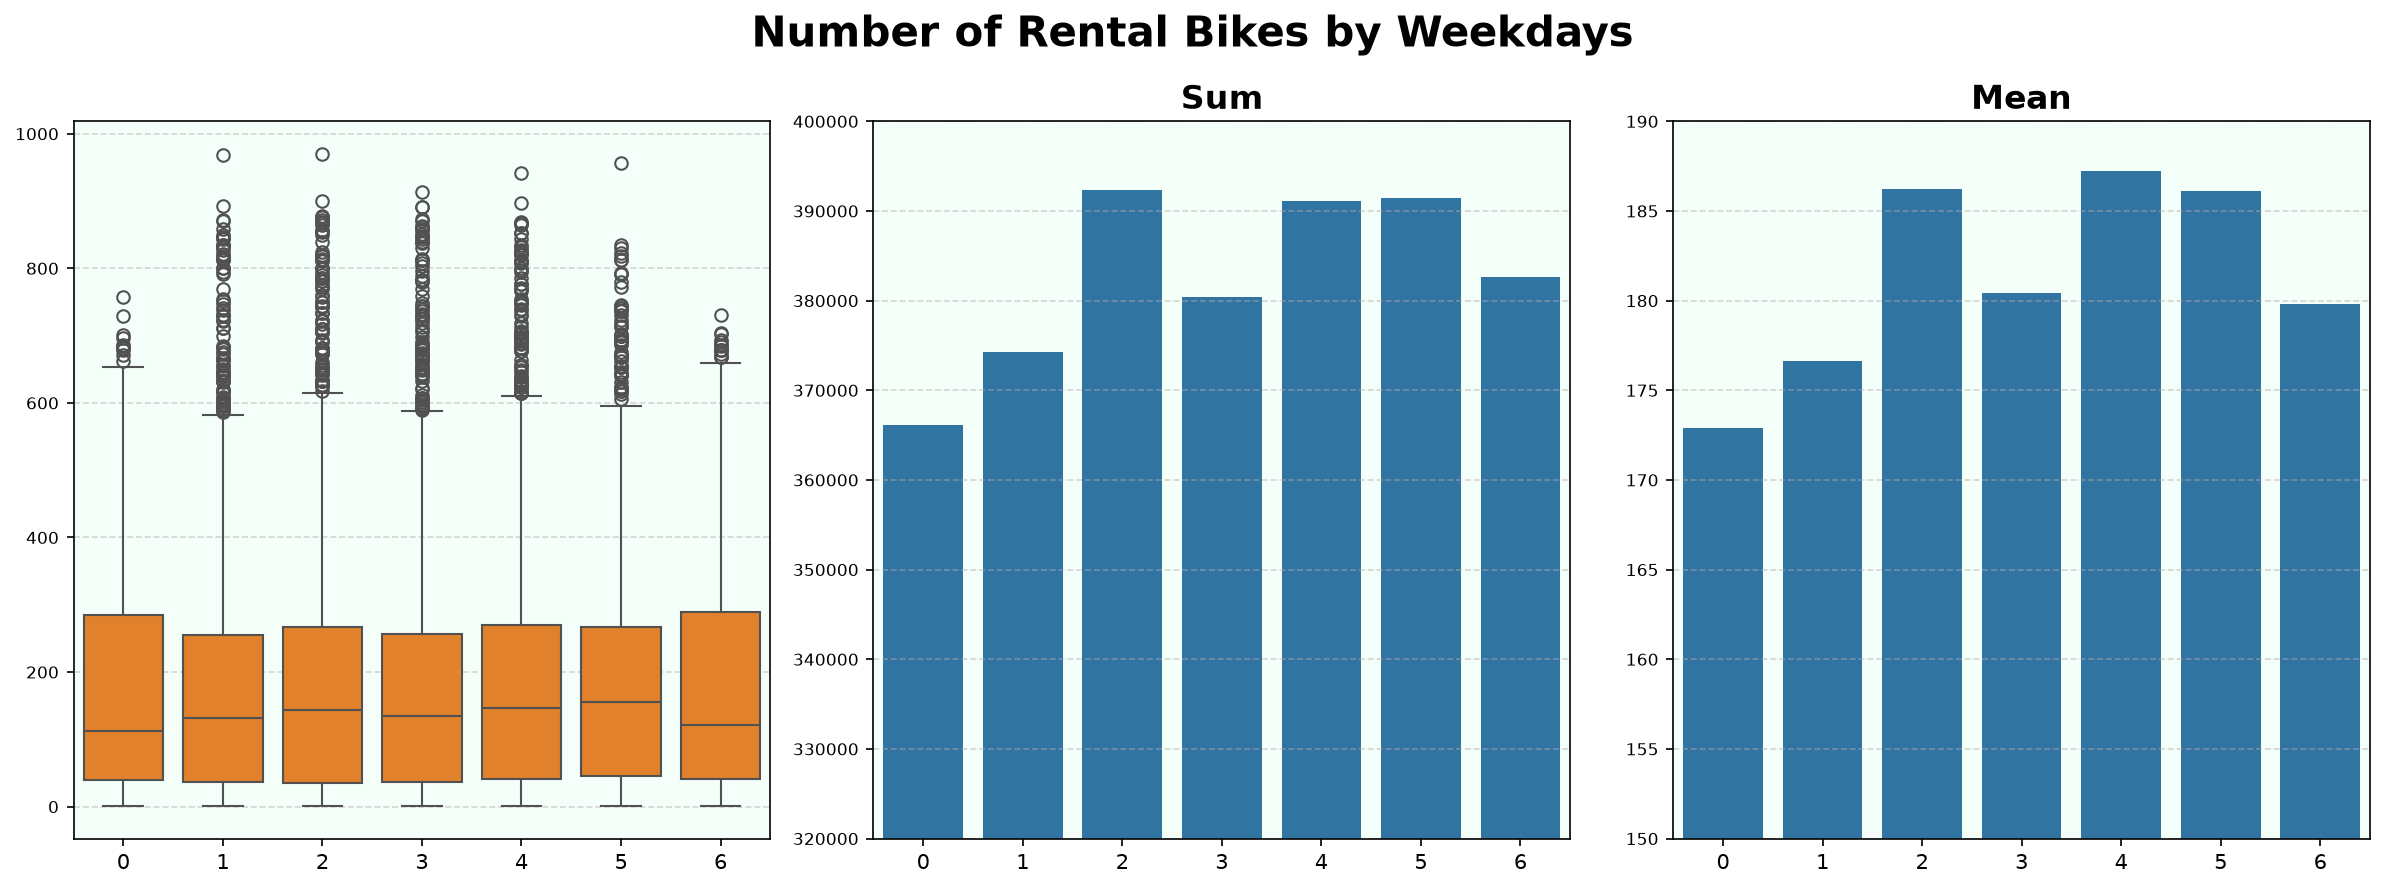

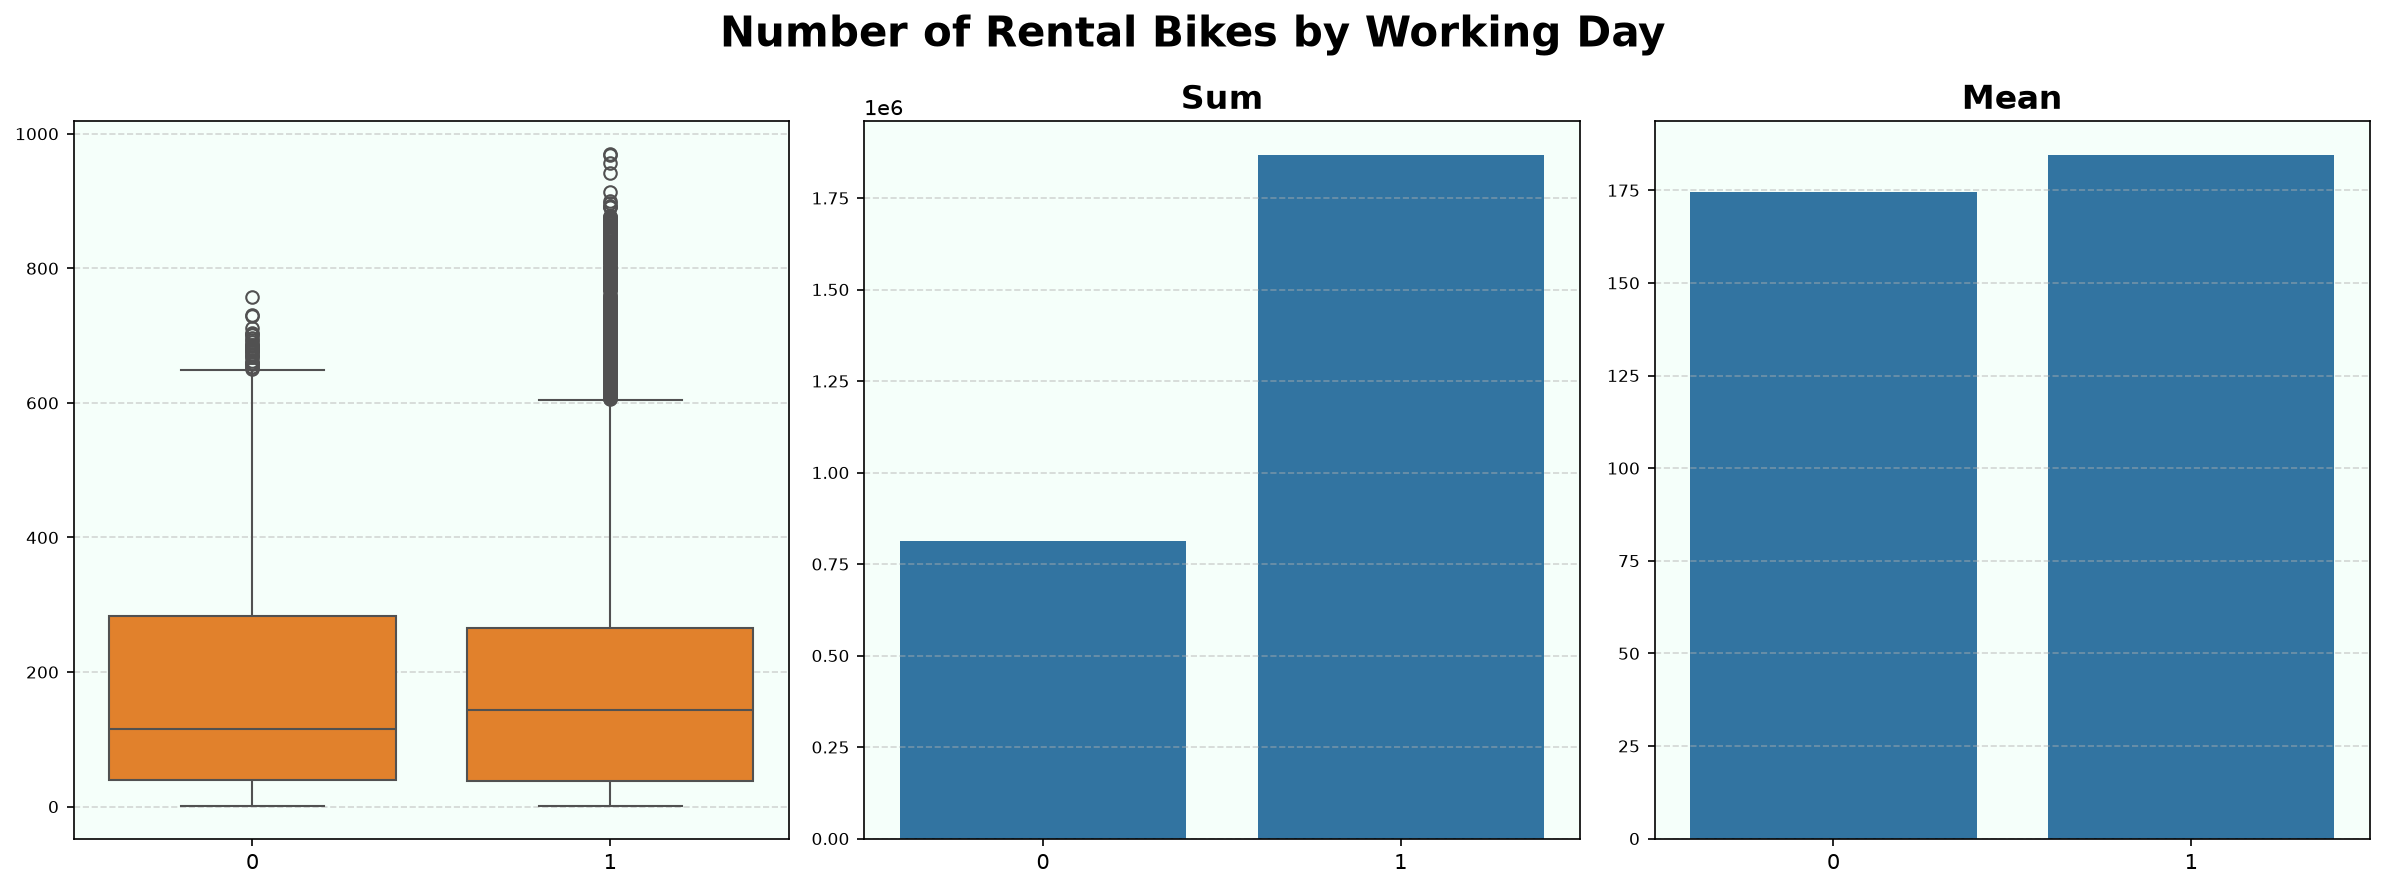

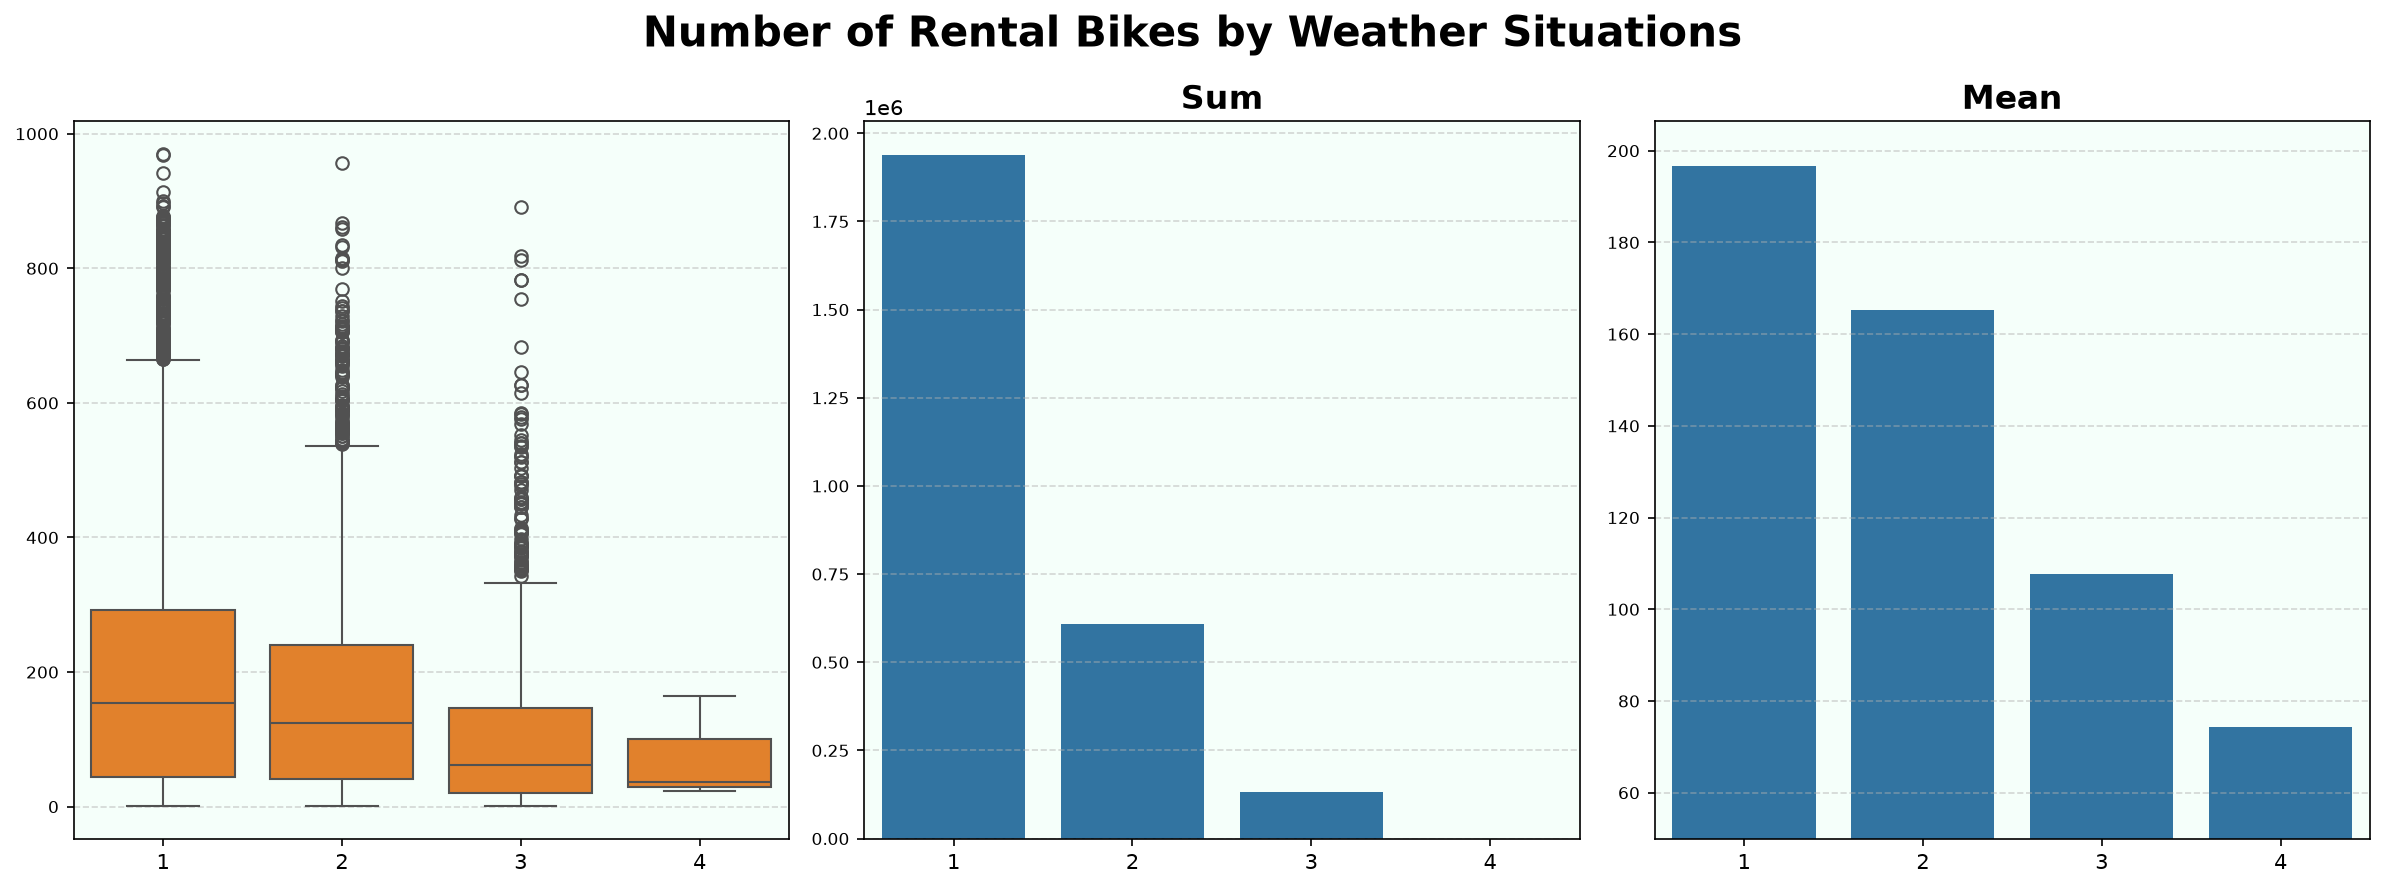

In [15]:
cat_corrected_labels = {'mnth': 'Months', 'holiday':'Holiday', 'weekday':'Weekdays', 'workingday':"Working Day", 'weathersit':'Weather Situations'}

for c in cat_cols:
    fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(16, 6), dpi=150)
    fig.suptitle(f"Number of Rental Bikes by {cat_corrected_labels.get(c)}", size=20, fontweight='bold')

    sns.boxplot(data=trainvaldf, x=c, y='cnt', ax=axes[0], color='tab:orange')

    sns.barplot(data=trainvaldf, x=c, y='cnt', ax=axes[1], errorbar=None, estimator='sum', color='tab:blue')
    axes[1].set_title("Sum", size=16, fontweight='bold')

    sns.barplot(data=trainvaldf, x=c, y='cnt', ax=axes[2], errorbar=None, estimator='mean', color='tab:blue')
    axes[2].set_title("Mean", size=16, fontweight='bold')

    for i in range(3):
        axes[i].set_xlabel("")
        axes[i].set_ylabel("")
        axes[i].tick_params(axis='y', labelsize=8)
        axes[i].set_facecolor('#F5FFFA')
        axes[i].grid(axis="y", linestyle="--", alpha=0.5)

    if c == 'weekday':
        axes[1].set_ylim(320000, 400000)
        axes[2].set_ylim(150, 190)
    if c == 'mnth':
        axes[1].set_ylim(50000, 360000)
        axes[2].set_ylim(50, 250)
    if c == 'weathersit':
        axes[2].set_ylim(50, None)

    plt.tight_layout()
    plt.show()

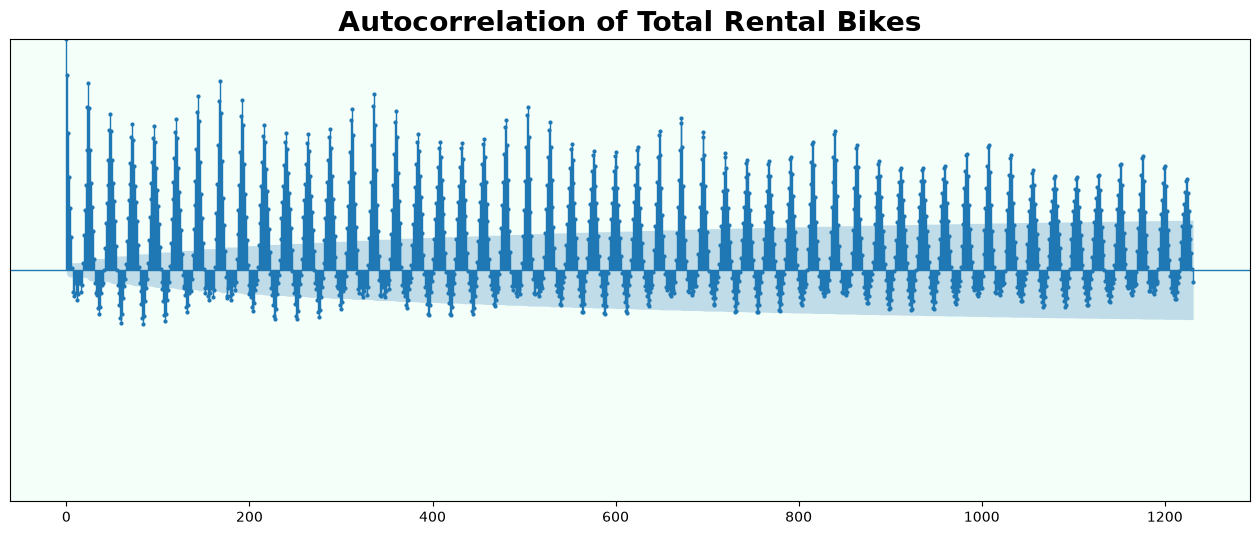

In [16]:
plt.figure(figsize=(16,6))
plot_acf(trainvaldf[target_feature], ax=plt.gca(), lags=trainvaldf.shape[0]//12, markersize=2, lw=1, vlines_kwargs={'lw':1})
plt.title("Autocorrelation of Total Rental Bikes", fontsize=20, fontweight='bold')
plt.gca().set_facecolor('#F5FFFA')
plt.yticks([])
plt.show()

In [18]:
traindf = rentt[:train_idx]
valdf = rentt[train_idx:val_idx]
testdf = rentt[val_idx:]

print(traindf.shape, '—', traindf.shape[0]//24, 'days', traindf.shape[0]%24, 'hours', '—', 'ends in:', traindf['dteday'].iloc[-1])
print(valdf.shape, '—', valdf.shape[0]//24, 'days', valdf.shape[0]%24, 'hours', '—', 'ends in:', valdf['dteday'].iloc[-1])
print(testdf.shape, '—', testdf.shape[0]//24, 'days', testdf.shape[0]%24, 'hours', '—', 'ends in:', testdf['dteday'].iloc[-1])

(13034, 13) — 543 days 2 hours — ends in: 2012-07-02 06:00:00
(1738, 13) — 72 days 10 hours — ends in: 2012-09-12 16:00:00
(2607, 13) — 108 days 15 hours — ends in: 2012-12-31 23:00:00


In [19]:
traindf.to_csv("data/hour_train.csv", index=False)
valdf.to_csv("data/hour_val.csv", index=False)
testdf.to_csv("data/hour_test.csv", index=False)